# Proyek 3: Agglomerative Hierarchical Clustering dengan Cosine Similarity pada BISINDO

**Metrik Jarak:** Cosine Distance (1 - Cosine Similarity)  
**Metode Linkage:** Complete Linkage (Maximum Dissimilarity)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Target Klaster:** K = 26 Klaster Alfabet BISINDO  
**Output Target:** `outputHAC/dendrogram_cosine.png`, `outputHAC/cluster_cosine.png`, `outputHAC/evaluasi_hac_cosine.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak Cosine mengukur deviasi sudut orientasi antarvektor gestur:
$$d_{\text{Cosine}}(x, y) = 1 - \frac{x \cdot y}{\|x\|_2 \|y\|_2}$$

Pada data yang telah dinormalisasi L2, pohon Complete Linkage mengelompokkan gestur tangan berdasarkan bentuk konfigurasi sendi jari tanpa terdistorsi oleh ukuran telapak atau panjang fisik lengan.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputHAC")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET_CLUSTERS = 26
RANDOM_STATE = 42

print(f"[INFO] Direktori: {BASE_DIR} | Target Klaster = {TARGET_CLUSTERS}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC | Target Klaster = 26


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

normalizer = Normalizer(norm='l2')
X_norm = normalizer.fit_transform(X_std)
print("[INFO] Fitur dinormalisasi L2 ke permukaan bola satuan (||x|| = 1).")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur dinormalisasi L2 ke permukaan bola satuan (||x|| = 1).


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC\outputHAC\dendrogram_cosine.png'


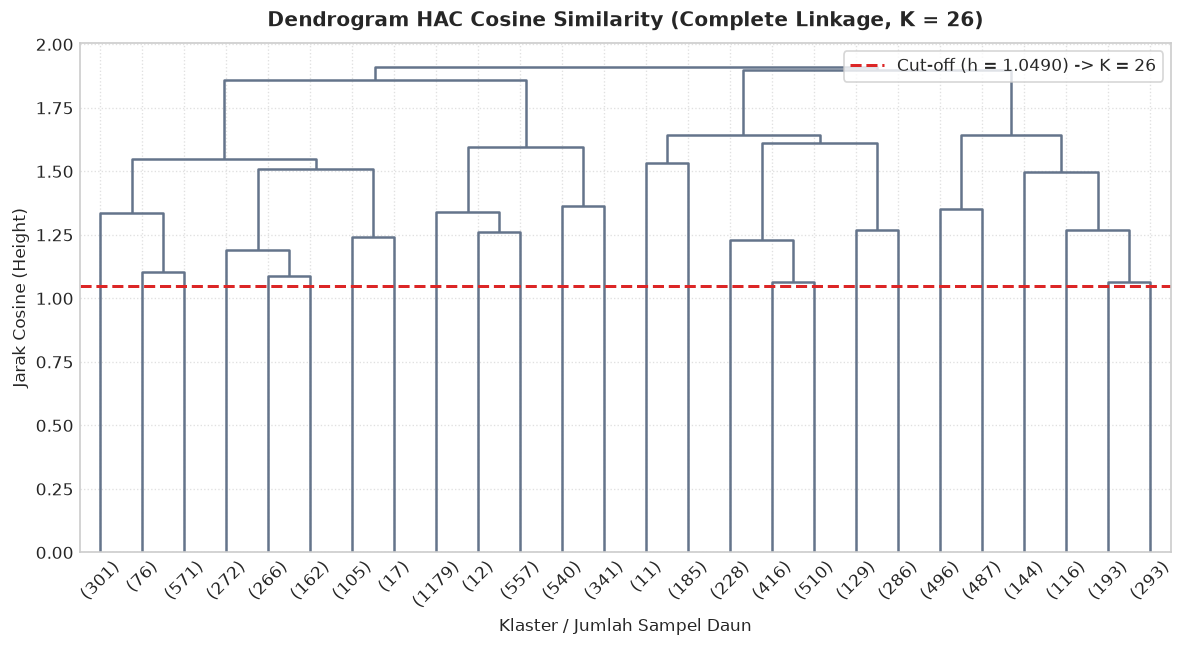

In [3]:
# =======================================================================
# 2. KONSTRUKSI LINKAGE DAN VISUALISASI DENDROGRAM COSINE
# =======================================================================
t0 = time.perf_counter()
Z = linkage(X_norm, method='complete', metric='cosine')
runtime_linkage = time.perf_counter() - t0

k_idx = TARGET_CLUSTERS - 1
h_cut = (Z[-k_idx, 2] + Z[-(k_idx + 1), 2]) / 2.0

plt.figure(figsize=(10, 5.5))
ddata = dendrogram(
    Z,
    truncate_mode='lastp',
    p=TARGET_CLUSTERS,
    color_threshold=h_cut,
    above_threshold_color='#64748B',
    show_leaf_counts=True
)

plt.axhline(y=h_cut, color='#DC2626', linestyle='--', linewidth=1.8, label=f'Cut-off (h = {h_cut:.4f}) -> K = {TARGET_CLUSTERS}')
plt.title(f'Dendrogram HAC Cosine Similarity (Complete Linkage, K = {TARGET_CLUSTERS})', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Klaster / Jumlah Sampel Daun', fontsize=10)
plt.ylabel('Jarak Cosine (Height)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()

dendro_path = os.path.join(OUTPUT_DIR, "dendrogram_cosine.png")
plt.savefig(dendro_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{dendro_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. EKSTRAKSI KLASTER DAN EVALUASI METRIK COSINE
# =======================================================================
labels = fcluster(Z, t=TARGET_CLUSTERS, criterion='maxclust') - 1
n_found = len(np.unique(labels))

sil = float(silhouette_score(X_norm, labels, metric='cosine'))
db = float(davies_bouldin_score(X_norm, labels))
ch = float(calinski_harabasz_score(X_norm, labels))

df_res = pd.DataFrame([{
    'Distance Metric': 'Cosine Similarity (Spherical)',
    'Linkage': 'Complete Linkage',
    'Clusters (K)': n_found,
    'Cut-off Height (h)': round(h_cut, 4),
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(runtime_linkage, 4)
}])

print("\n" + "="*85)
print(df_res.to_string(index=False))
print("="*85)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_hac_cosine.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_cosine'] = labels

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")


              Distance Metric          Linkage  Clusters (K)  Cut-off Height (h)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
Cosine Similarity (Spherical) Complete Linkage            26               1.049                0.1839                    1.8357                       818.14                  1.8523


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC\outputHAC\evaluasi_hac_cosine.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC\outputHAC\cluster_cosine.png'


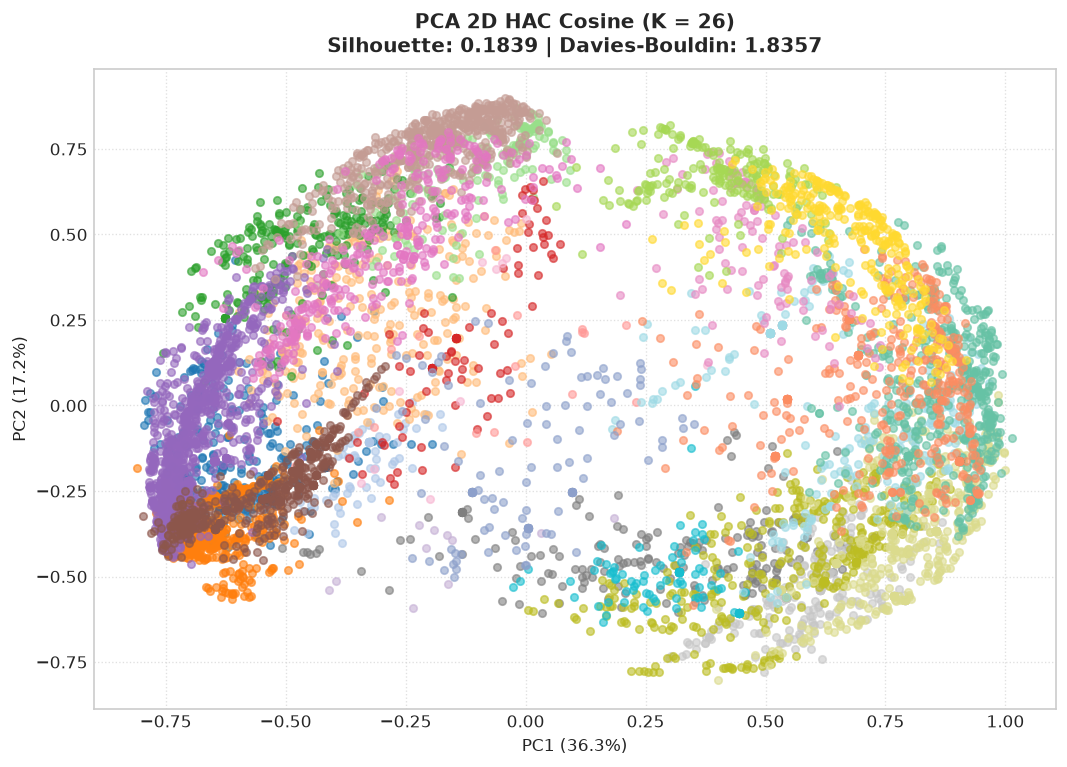

In [5]:
# =======================================================================
# 4. VISUALISASI PCA 2D KLASTERISASI HAC COSINE
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_norm)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

for k in range(n_found):
    mask = (labels == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.60, s=20)

plt.title(f'PCA 2D HAC Cosine (K = {n_found})\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_cosine.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()